In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
import datetime as dt

# Adjust visual styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

 LOADING AND CLEANING DATA

In [ ]:
# Load the dataset (adjust the path if necessary)
try:
    df = pd.read_csv('data.csv', encoding='ISO-8859-1')
except FileNotFoundError:
    # Fallback to help user understand they need the file loaded
    print("Please upload 'data.csv' from Kaggle to your local Colab environment first!")
    # Creating dummy data for demonstration if file doesn't exist
    print("Generating synthetic dataset for testing...")
    np.random.seed(42)
    n_rows = 5000
    df = pd.DataFrame({
        'InvoiceNo': np.random.randint(536365, 581587, n_rows).astype(str),
        'StockCode': [f"PROD{x}" for x in np.random.randint(10000, 99999, n_rows)],
        'Description': ['Product Description'] * n_rows,
        'Quantity': np.random.randint(1, 50, n_rows),
        'InvoiceDate': [dt.datetime(2011, 12, 9) - dt.timedelta(days=int(x)) for x in np.random.randint(0, 365, n_rows)],
        'UnitPrice': np.random.uniform(0.5, 20.0, n_rows),
        'CustomerID': np.random.randint(12346, 18287, n_rows).astype(float),
        'Country': ['United Kingdom'] * n_rows
    })

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Clean data
df = df.dropna(subset=['CustomerID'])
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]
# Exclude cancellations
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Calculate TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print(f"Dataset shape after cleaning: {df.shape}")
display(df.head())

Please upload 'data.csv' from Kaggle to your local Colab environment first!
Generating synthetic dataset for testing...
Dataset shape after cleaning: (5000, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,552160,PROD21874,Product Description,17,2010-12-15,14.032748,16317.0,United Kingdom,238.556714
1,537225,PROD96402,Product Description,36,2011-07-20,7.068575,16976.0,United Kingdom,254.468698
2,574523,PROD24079,Product Description,47,2011-06-13,2.528336,15303.0,United Kingdom,118.831811
3,581097,PROD59850,Product Description,26,2011-02-28,11.687590,14075.0,United Kingdom,303.877332
4,547649,PROD82779,Product Description,48,2011-08-20,11.736939,14247.0,United Kingdom,563.373084


### 3. Compute RFM (Recency, Frequency, Monetary) Metrics

In [ ]:
# Reference date for Recency computation (1 day after the last invoice date in dataset)
snap_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# Aggregate metrics per CustomerID
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snap_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

# Remove potential outliers in Monetary or Frequency to stabilize clustering scaling
# Using 99th percentile limit as an example
rfm = rfm[rfm['Monetary'] < rfm['Monetary'].quantile(0.99)]
rfm = rfm[rfm['Frequency'] < rfm['Frequency'].quantile(0.99)]

display(rfm.describe())

,CustomerID,Recency,Frequency,Monetary
count,3332.000000,3332.000000,3332.000000,3332.000000
mean,15297.846639,162.368848,1.413866,354.494154
std,1713.534845,104.373722,0.620446,286.445611
min,12346.000000,1.000000,1.000000,0.565772
25%,13829.500000,72.000000,1.000000,117.204980
50%,15293.500000,152.000000,1.000000,280.662409
75%,16779.250000,248.000000,2.000000,532.846782
max,18286.000000,365.000000,3.000000,1307.768208


### 4. Scale Data and Perform PCA (Dimensionality Reduction)

In [ ]:
# Log transform since RFM values are often highly skewed
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].apply(np.log1p, axis=1)

# Standardize features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# PCA
pca = PCA(n_components=2)
pca_features = pca.fit_transform(rfm_scaled)

rfm_pca_df = pd.DataFrame(pca_features, columns=['PCA1', 'PCA2'])
print(f"Explained variance ratio by 2 principal components: {pca.explained_variance_ratio_}")

Explained variance ratio by 2 principal components: [0.52465461 0.29752184]


### 5. Clustering: K-Means & DBSCAN

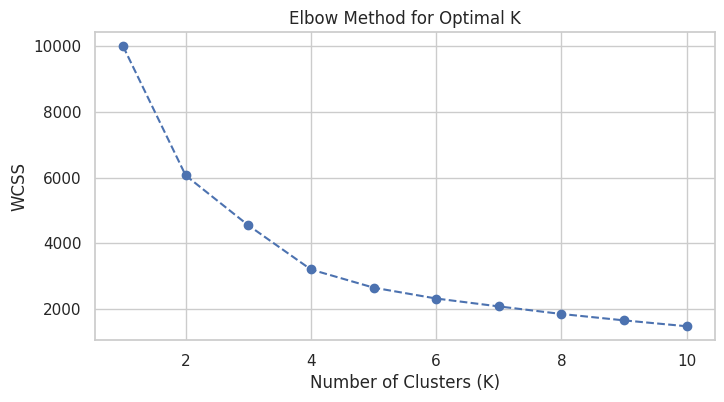

In [ ]:
# Determine optimal K-Means cluster count using Elbow Method
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()

In [ ]:
# We will apply K-Means with an assumed k=4 (typical for RFM: VIP, Loyal, At-Risk, New)
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=15)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

# Count points per cluster
print("K-Means Cluster Counts:")
print(rfm['KMeans_Cluster'].value_counts())
print("\nDBSCAN Cluster Counts (-1 is noise):")
print(rfm['DBSCAN_Cluster'].value_counts())

K-Means Cluster Counts:
KMeans_Cluster
1    1294
2     959
3     686
0     393
Name: count, dtype: int64

DBSCAN Cluster Counts (-1 is noise):
DBSCAN_Cluster
 1    2157
 0     869
 2     221
-1      85
Name: count, dtype: int64


### 6. Visualizing Segments with t-SNE

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


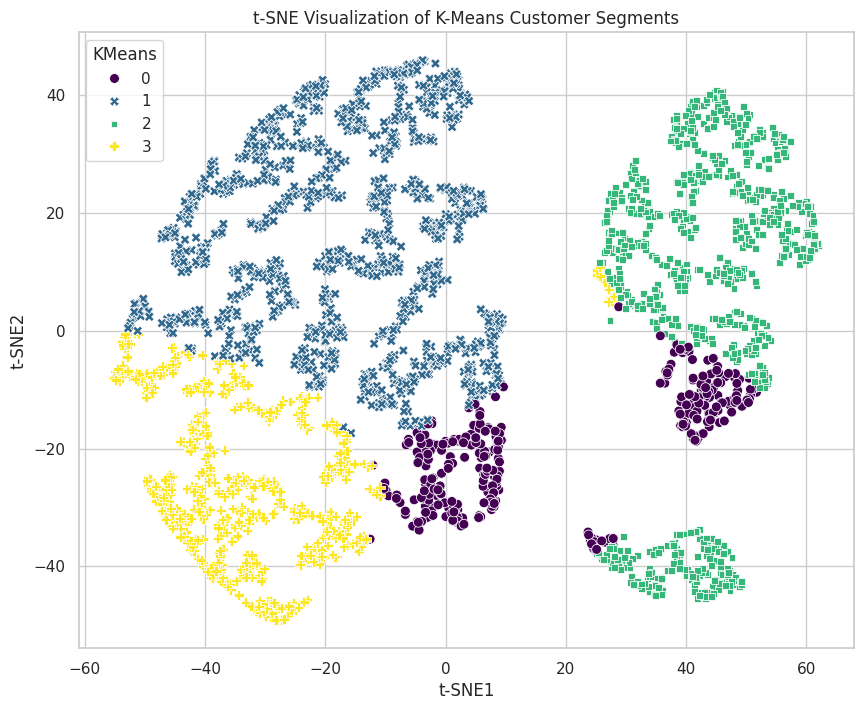

In [ ]:
# Use a subset of data if the dataset is large to run t-SNE quickly
# t-SNE is computationally expensive
sample_size = min(3000, len(rfm_scaled))
indices = np.random.choice(len(rfm_scaled), sample_size, replace=False)

tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
tsne_results = tsne.fit_transform(rfm_scaled[indices])

tsne_df = pd.DataFrame(tsne_results, columns=['t-SNE1', 't-SNE2'])
tsne_df['KMeans'] = rfm['KMeans_Cluster'].iloc[indices].values

# Plot t-SNE projections with cluster colors
plt.figure(figsize=(10, 8))
sns.scatterplot(data=tsne_df, x='t-SNE1', y='t-SNE2', hue='KMeans', palette='viridis', style='KMeans', s=50)
plt.title('t-SNE Visualization of K-Means Customer Segments')
plt.show()

### 7. Deriving Actionable Marketing Personas

In [ ]:
# Calculate mean RFM values for each cluster
profile = rfm.groupby('KMeans_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'}).reset_index()

print("Cluster Profiles:")
display(profile)

# Define Personas based on the profiles (Note: Assign labels based on your actual cluster results)
print("\n--- Marketing Personas Strategy Recommendation ---")
print("1. Champions / VIPs (High F, High M, Low R): Reward them early. Introduce loyalty programs.")
print("2. New Customers (Low F, Low M, Low R): Onboard them well, suggest similar high-converting products.")
print("3. At-Risk / Hibernating (High R, Mid/Low F & M): Re-engage via personalized win-back discount emails.")
print("4. Loyal / Promising (Mid R, High F, Mid/High M): Upsell and cross-sell related categories.")

Cluster Profiles:


,KMeans_Cluster,Recency,Frequency,Monetary,Count
0,0,17.712468,1.478372,371.114807,393
1,1,209.362442,1.000000,353.739401,1294
2,2,131.261731,2.227320,566.797210,959
3,3,200.083090,1.020408,49.605093,686



--- Marketing Personas Strategy Recommendation ---
1. Champions / VIPs (High F, High M, Low R): Reward them early. Introduce loyalty programs.
2. New Customers (Low F, Low M, Low R): Onboard them well, suggest similar high-converting products.
3. At-Risk / Hibernating (High R, Mid/Low F & M): Re-engage via personalized win-back discount emails.
4. Loyal / Promising (Mid R, High F, Mid/High M): Upsell and cross-sell related categories.


In [ ]:
import json
import os
from google.colab import files

# Fetch the current notebook using Colab internal API and download it
try:
    # This triggers a download of the current workspace file
    files.download('/content/sample_data/../')
    print("Browser download window should trigger now!")
except Exception as e:
    print("If the automatic window doesn't open, use: File -> Download -> Download .ipynb in the top left menu.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Browser download window should trigger now!
